# Klasifikasi Kondisi Udara Relatif: SVM vs ANN dengan Penanganan Imbalanced Data
**UAS Statistical Machine Learning** — Dataset: *Air Quality Dataset* (log sensor, 1.500 observasi)

| Tahap | Isi |
|---|---|
| A | Pemeriksaan data, EDA, multikolinearitas |
| B | Pembentukan label kelas (relatif) |
| C | Diagnosis imbalanced data |
| D | Split stratified **sebelum** resampling |
| E | Pipeline anti-leakage: Scaler → Resampler → Model; tuning dengan CV |
| F | Evaluasi test set + selang kepercayaan bootstrap + uji beda SVM vs ANN |
| G | Interpretasi (permutation importance), diagnostik ANN, decision boundary SVM |
| H | Uji ketahanan: split berdasarkan waktu, stabilitas seed ANN |

> **Catatan framing:** dataset tidak memiliki label. Kelas dibentuk dari persentil data sendiri, sehingga
> hasil dibaca sebagai *kondisi udara relatif dalam sesi pengukuran ini*, bukan status kesehatan menurut standar WHO/EPA/ISPU.

In [ ]:
!pip -q install imbalanced-learn openpyxl

In [ ]:
import warnings, time
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder, label_binarize
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.decomposition import PCA
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, precision_score, recall_score,
                             matthews_corrcoef, roc_auc_score, average_precision_score, classification_report,
                             ConfusionMatrixDisplay, roc_curve, precision_recall_curve)

from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.combine import SMOTETomek

# ---------- Konfigurasi ----------
SEED = 42
TEST_SIZE = 0.20
N_FOLDS = 5
N_BOOT = 2000
PALETTE = {'Good': '#009E73', 'Moderate': '#E69F00', 'Unhealthy': '#D55E00'}
sns.set_theme(style='whitegrid', font_scale=0.95)
np.random.seed(SEED)

## A. Data, pemeriksaan kualitas, dan EDA

In [ ]:
try:                                           # Colab: unggah file
    from google.colab import files
    DATA_PATH = next(iter(files.upload()))
except ImportError:                            # lokal
    DATA_PATH = 'air_quality_dataset.xlsx'

raw = pd.read_excel(DATA_PATH)
raw['Timestamp'] = pd.to_datetime(raw['Timestamp'])
raw = raw.sort_values('Timestamp').reset_index(drop=True)

dt = raw['Timestamp'].diff().dt.total_seconds().dropna()
print(f'Baris x kolom      : {raw.shape}')
print(f'Periode            : {raw.Timestamp.min()}  s.d.  {raw.Timestamp.max()}')
print(f'Interval median    : {dt.median():.0f} detik (maks {dt.max():.0f} detik)')
print(f'Missing / duplikat : {raw.isna().sum().sum()} / {raw.duplicated().sum()}')
display(raw.drop(columns='Timestamp').describe().T[['mean', 'std', 'min', '50%', 'max']].round(3))

Saving air quality dataset.xlsx to air quality dataset.xlsx
Baris x kolom      : (1500, 12)
Periode            : 2025-07-09 12:56:31  s.d.  2025-07-09 15:21:50
Interval median    : 6 detik (maks 7 detik)
Missing / duplikat : 0 / 0


,mean,std,min,50%,max
Temperature (C),27.588,0.072,27.444,27.590,27.812
Humidity (%),40.695,0.412,40.107,40.564,42.104
Pressure (hPa),888.151,0.529,887.206,888.130,889.102
Gas Resistance (Ohms),53780.205,1384.664,42146.000,53657.000,65222.000
PM2.5,6.231,1.134,3.000,6.000,11.000
TVOC (ppb),8.312,9.649,0.000,5.000,46.000
eCO2 (ppm),403.519,5.466,400.000,400.000,453.000
VOC Index,99.841,4.090,92.000,100.000,112.000
MQ135 Value,80.689,4.154,70.000,83.000,104.000
Voltage,0.260,0.013,0.226,0.268,0.335


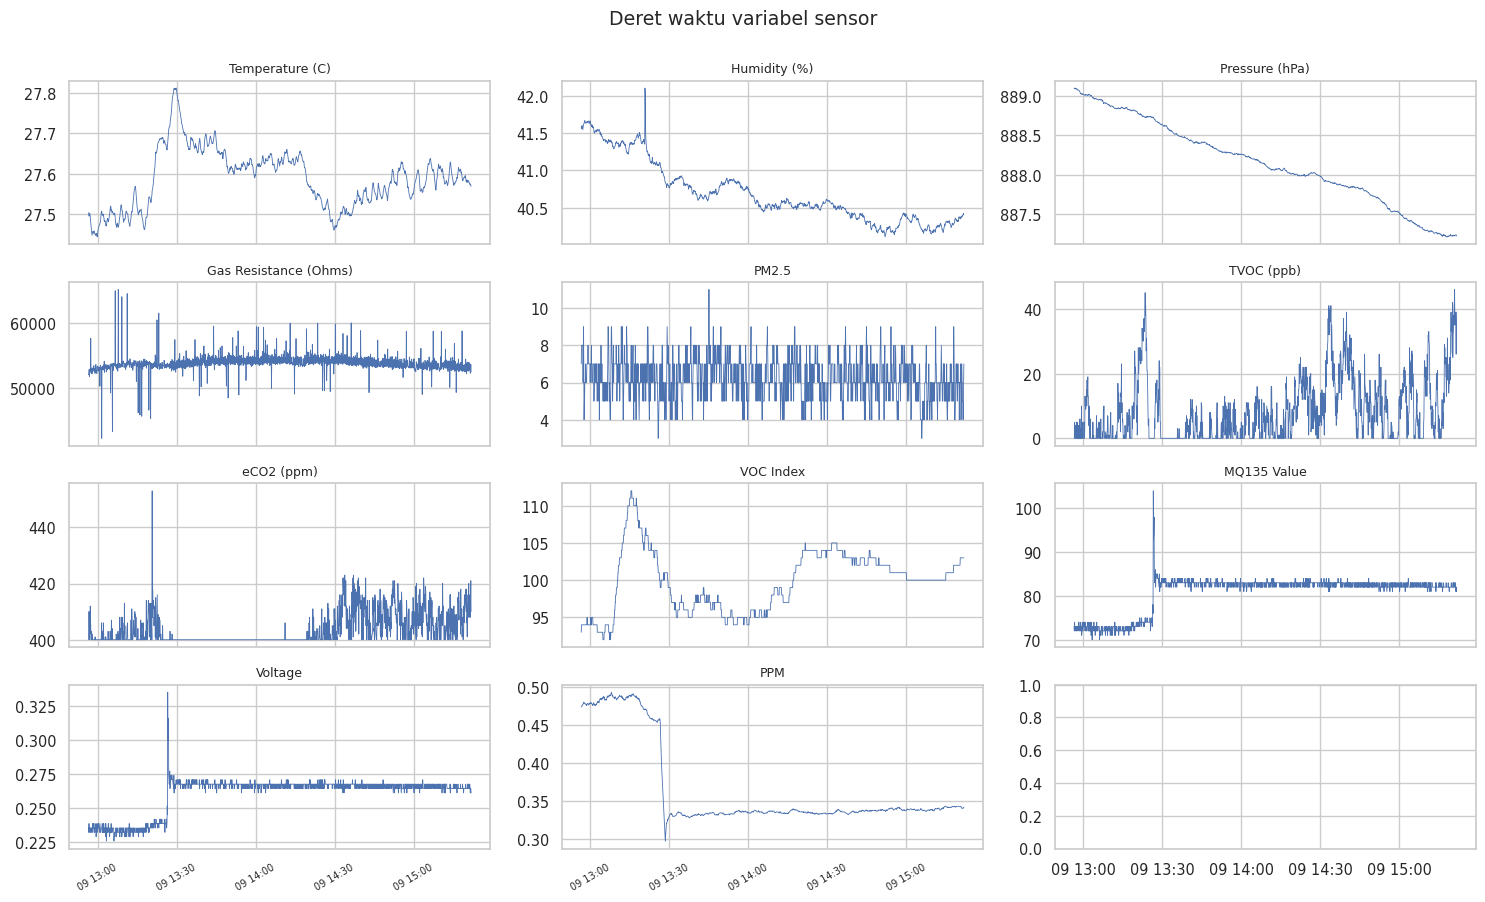

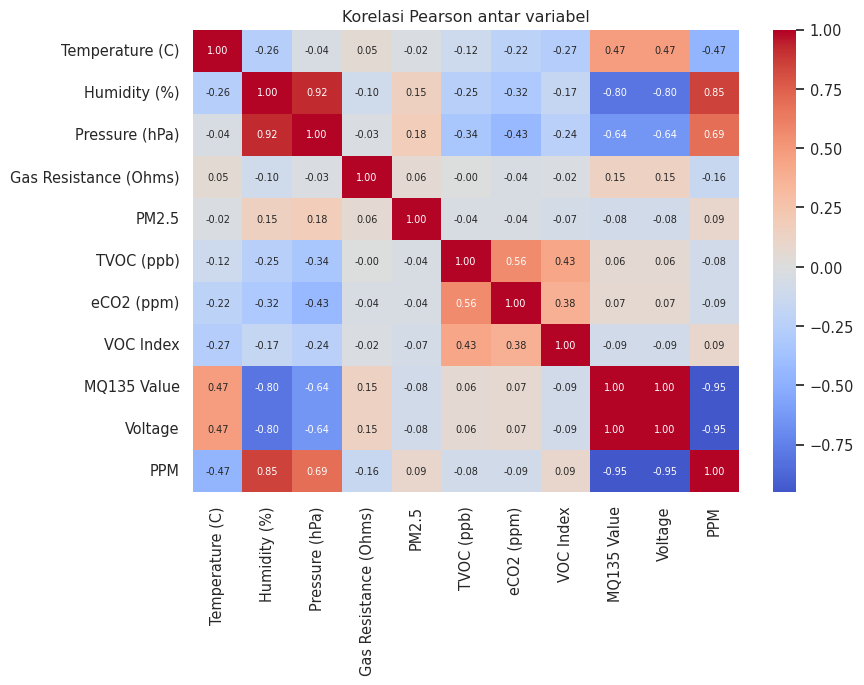

In [ ]:
sensor_cols = [c for c in raw.columns if c != 'Timestamp']

fig, axes = plt.subplots(4, 3, figsize=(15, 9), sharex=True)
for ax, c in zip(axes.ravel(), sensor_cols):
    ax.plot(raw['Timestamp'], raw[c], lw=0.6); ax.set_title(c, fontsize=9)
    ax.tick_params(axis='x', rotation=30, labelsize=7)
fig.suptitle('Deret waktu variabel sensor', y=1.0); plt.tight_layout(); plt.show()

plt.figure(figsize=(9, 7))
sns.heatmap(raw[sensor_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, annot_kws={'size': 7})
plt.title('Korelasi Pearson antar variabel'); plt.tight_layout(); plt.show()

In [ ]:
# ----- Pembagian peran variabel -----
# Variabel "polutan/indikator kualitas" -> dipakai MEMBENTUK label.
# Variabel "lingkungan/sensor pendukung" -> dipakai sebagai FITUR (X).
LABEL_VARS = ['PM2.5', 'TVOC (ppb)', 'eCO2 (ppm)', 'VOC Index', 'PPM']
FEATURE_CANDIDATES = ['Temperature (C)', 'Humidity (%)', 'Pressure (hPa)',
                      'Gas Resistance (Ohms)', 'MQ135 Value', 'Voltage']

def vif(frame):
    Z = (frame - frame.mean()) / frame.std()
    out = {}
    for c in Z:
        A = np.c_[np.ones(len(Z)), Z.drop(columns=c).values]
        b = np.linalg.lstsq(A, Z[c].values, rcond=None)[0]
        r2 = 1 - (Z[c].values - A @ b).var() / Z[c].var()
        out[c] = np.inf if r2 > 1 - 1e-9 else 1 / (1 - r2)
    return pd.Series(out, name='VIF').sort_values(ascending=False)

print('Rasio MQ135 / Voltage ->', (raw['MQ135 Value'] / raw['Voltage']).round(6).unique()[:3], '(konstan: dua kolom identik)')
print('\nVIF kandidat fitur:'); display(vif(raw[FEATURE_CANDIDATES]).to_frame())

FEATURES = [c for c in FEATURE_CANDIDATES if c != 'Voltage']       # buang duplikat linear
print('Fitur akhir:', FEATURES); display(vif(raw[FEATURES]).to_frame())

Rasio MQ135 / Voltage -> [310.] (konstan: dua kolom identik)

VIF kandidat fitur:


,VIF
MQ135 Value,inf
Voltage,inf
Humidity (%),13.574759
Pressure (hPa),9.211760
Temperature (C),1.637058
Gas Resistance (Ohms),1.054114


Fitur akhir: ['Temperature (C)', 'Humidity (%)', 'Pressure (hPa)', 'Gas Resistance (Ohms)', 'MQ135 Value']


,VIF
Humidity (%),13.574759
Pressure (hPa),9.211760
MQ135 Value,3.785746
Temperature (C),1.637058
Gas Resistance (Ohms),1.054114


## B. Pembentukan label
Skor = banyaknya variabel (dari 5 variabel indikator) yang nilainya **di atas persentil ke-75**.
`skor ≥ 3 → Unhealthy`, `skor = 2 → Moderate`, selain itu `Good`.

Ambang persentil diperlakukan sebagai **definisi label** (aturan tetap), bukan parameter yang dipelajari model.
Variabel pembentuk label **tidak** menjadi fitur.

In [ ]:
P = 0.75
thr = raw[LABEL_VARS].quantile(P)
display(thr.to_frame(f'Ambang P{int(P*100)}').round(3))

score = sum((raw[v] > thr[v]).astype(int) for v in LABEL_VARS)
raw['label'] = np.select([score >= 3, score == 2], ['Unhealthy', 'Moderate'], default='Good')

CLASSES = ['Good', 'Moderate', 'Unhealthy']            # urutan tetap
le = LabelEncoder().fit(CLASSES)
y_all = le.transform(raw['label'])
X_all = raw[FEATURES]
print('Pemetaan:', dict(zip(le.classes_, le.transform(le.classes_))))

,Ambang P75
PM2.5,7.000
TVOC (ppb),13.000
eCO2 (ppm),406.000
VOC Index,103.000
PPM,0.342


Pemetaan: {np.str_('Good'): np.int64(0), np.str_('Moderate'): np.int64(1), np.str_('Unhealthy'): np.int64(2)}


## C. Diagnosis imbalanced data
Proporsi kelas $\pi_k = n_k/n$ dan **Imbalance Ratio** $IR = n_{mayoritas}/n_{minoritas}$.
*Accuracy paradox*: model yang selalu menebak kelas mayoritas.

              n      %  bobot w=n/(K*n_k)
Good       1041  69.40              0.480
Moderate    307  20.47              1.629
Unhealthy   152  10.13              3.289

IR = 1041 / 152 = 6.85
Model "selalu Good": accuracy=0.694 | balanced acc=0.333 | macro-F1=0.273


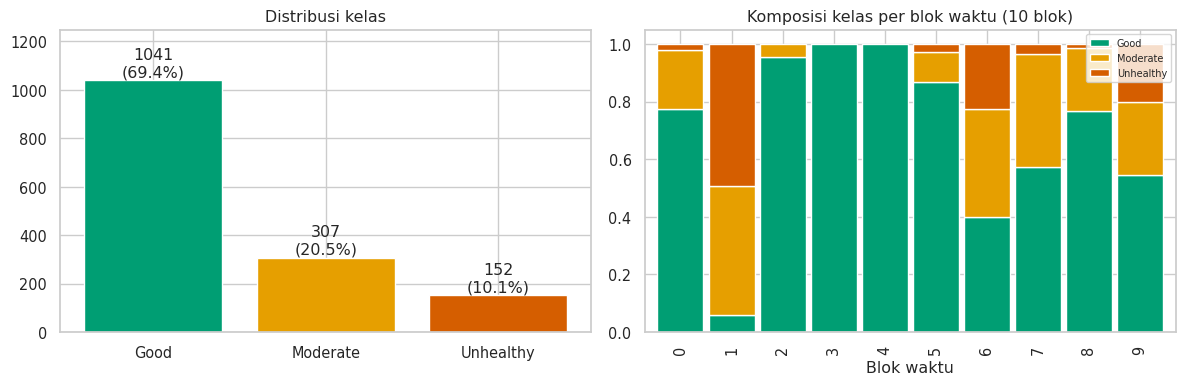

In [ ]:
n_k = pd.Series(y_all).value_counts().sort_index(); n_k.index = le.classes_
print(pd.DataFrame({'n': n_k, '%': (100 * n_k / n_k.sum()).round(2),
                    'bobot w=n/(K*n_k)': (n_k.sum() / (3 * n_k)).round(3)}).to_string())
IR = n_k.max() / n_k.min(); print(f'\nIR = {n_k.max()} / {n_k.min()} = {IR:.2f}')

maj = np.full_like(y_all, n_k.values.argmax())
print(f'Model "selalu {n_k.idxmax()}": accuracy={accuracy_score(y_all, maj):.3f} | '
      f'balanced acc={balanced_accuracy_score(y_all, maj):.3f} | macro-F1={f1_score(y_all, maj, average="macro"):.3f}')

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(n_k.index, n_k.values, color=[PALETTE[c] for c in n_k.index])
for i, v in enumerate(n_k.values): ax[0].text(i, v + 15, f'{v}\n({100*v/n_k.sum():.1f}%)', ha='center')
ax[0].set_title('Distribusi kelas'); ax[0].set_ylim(0, n_k.max() * 1.2)
raw['code'] = y_all
blk = pd.cut(np.arange(len(raw)), 10, labels=False)
pd.crosstab(blk, raw['label'], normalize='index')[CLASSES].plot(kind='bar', stacked=True, ax=ax[1],
                                                                color=[PALETTE[c] for c in CLASSES], width=0.9)
ax[1].set_title('Komposisi kelas per blok waktu (10 blok)'); ax[1].set_xlabel('Blok waktu'); ax[1].legend(loc='upper right', fontsize=7)
plt.tight_layout(); plt.show()

## D. Split data : stratified, dilakukan SEBELUM resampling

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X_all, y_all, test_size=TEST_SIZE, stratify=y_all, random_state=SEED)
cv = StratifiedKFold(N_FOLDS, shuffle=True, random_state=SEED)
print(pd.DataFrame({'train': np.bincount(y_train), 'test': np.bincount(y_test)}, index=CLASSES))

# Ilustrasi efek tiap resampler pada DATA TRAINING saja
sc = StandardScaler().fit(X_train); Xs = sc.transform(X_train)
show = {'Asli': None, 'Random Oversampling': RandomOverSampler(random_state=SEED),
        'SMOTE': SMOTE(random_state=SEED), 'SMOTE-Tomek': SMOTETomek(random_state=SEED)}
tab = {}
for k, s in show.items():
    tab[k] = np.bincount(y_train) if s is None else np.bincount(s.fit_resample(Xs, y_train)[1])
display(pd.DataFrame(tab, index=CLASSES).T)

           train  test
Good         833   208
Moderate     245    62
Unhealthy    122    30


,Good,Moderate,Unhealthy
Asli,833,245,122
Random Oversampling,833,833,833
SMOTE,833,833,833
SMOTE-Tomek,808,802,823


## E. Pipeline, strategi imbalance, dan tuning
**Strategi**: Baseline · Class Weight (hanya SVM, karena `MLPClassifier` tidak punya `class_weight`) · Random Oversampling · SMOTE · SMOTE-Tomek.

**Anti-leakage**: `Pipeline` dari `imblearn` — scaler dipelajari dan resampling dilakukan *hanya pada bagian training tiap fold*; fold validasi dan test tidak pernah di-resampling.

**Tuning** (Stratified 5-fold, skor utama `f1_macro`, `balanced_accuracy` dicatat):
* SVM RBF: $C \in \{0.1, 1, 10, 100\}$ (skala log), $\gamma \in \{scale, 0.01, 0.1, 1\}$
* ANN: arsitektur hidden layer, regularisasi L2 `alpha`, ReLU + Adam + early stopping

In [ ]:
def build(model, strategy, seed=SEED):
    steps = [('scaler', StandardScaler())]
    if   strategy == 'Random Oversampling': steps.append(('resampler', RandomOverSampler(random_state=seed)))
    elif strategy == 'SMOTE':               steps.append(('resampler', SMOTE(random_state=seed)))
    elif strategy == 'SMOTE-Tomek':         steps.append(('resampler', SMOTETomek(random_state=seed)))
    if model == 'SVM':
        est = SVC(kernel='rbf', class_weight='balanced' if strategy == 'Class Weight' else None, random_state=seed)
    else:
        est = MLPClassifier(activation='relu', solver='adam', early_stopping=True, validation_fraction=0.1,
                            n_iter_no_change=10, max_iter=1000, random_state=seed)
    steps.append(('model', est))
    return Pipeline(steps)

GRID = {'SVM': {'model__C': [0.1, 1, 10, 100, 1000], 'model__gamma': ['scale', 0.01, 0.1, 1, 10]},
        'ANN': {'model__hidden_layer_sizes': [(16, 8), (32,), (64, 32)], 'model__alpha': [1e-4, 1e-2, 1.0]}}
STRATS = {'SVM': ['Baseline', 'Class Weight', 'Random Oversampling', 'SMOTE', 'SMOTE-Tomek'],
          'ANN': ['Baseline', 'Random Oversampling', 'SMOTE', 'SMOTE-Tomek']}

fits, t0 = {}, time.time()
for m in STRATS:
    for s in STRATS[m]:
        gs = GridSearchCV(build(m, s), GRID[m], cv=cv, n_jobs=-1, refit='f1_macro',
                          scoring={'f1_macro': 'f1_macro', 'balanced_accuracy': 'balanced_accuracy'})
        fits[(m, s)] = gs.fit(X_train, y_train)
        print(f'{m} | {s:20s} | CV F1-macro = {gs.best_score_:.3f}  | {gs.best_params_}')
print(f'\nTotal waktu tuning: {time.time() - t0:.0f} detik')

SVM | Baseline             | CV F1-macro = 0.653  | {'model__C': 1000, 'model__gamma': 'scale'}
SVM | Class Weight         | CV F1-macro = 0.641  | {'model__C': 1000, 'model__gamma': 'scale'}
SVM | Random Oversampling  | CV F1-macro = 0.639  | {'model__C': 100, 'model__gamma': 1}
SVM | SMOTE                | CV F1-macro = 0.636  | {'model__C': 1000, 'model__gamma': 1}
SVM | SMOTE-Tomek          | CV F1-macro = 0.628  | {'model__C': 1, 'model__gamma': 10}
ANN | Baseline             | CV F1-macro = 0.307  | {'model__alpha': 0.0001, 'model__hidden_layer_sizes': (64, 32)}
ANN | Random Oversampling  | CV F1-macro = 0.518  | {'model__alpha': 0.01, 'model__hidden_layer_sizes': (64, 32)}
ANN | SMOTE                | CV F1-macro = 0.552  | {'model__alpha': 0.0001, 'model__hidden_layer_sizes': (64, 32)}
ANN | SMOTE-Tomek          | CV F1-macro = 0.532  | {'model__alpha': 0.0001, 'model__hidden_layer_sizes': (64, 32)}

Total waktu tuning: 141 detik


## F. Evaluasi pada test set

In [ ]:
def scores_of(est, X):
    return est.predict_proba(X) if hasattr(est, 'predict_proba') else est.decision_function(X)

def ovr_mean(y, S, fn):
    Y = label_binarize(y, classes=[0, 1, 2]); return np.mean([fn(Y[:, k], S[:, k]) for k in range(3)])

rows = []
for (m, s), gs in fits.items():
    est, i = gs.best_estimator_, gs.best_index_
    pt, ptr, S = est.predict(X_test), est.predict(X_train), scores_of(est, X_test)
    rows.append(dict(Model=m, Strategi=s,
        CV_F1=gs.cv_results_['mean_test_f1_macro'][i], CV_F1_sd=gs.cv_results_['std_test_f1_macro'][i],
        Train_F1=f1_score(y_train, ptr, average='macro'),
        Test_Acc=accuracy_score(y_test, pt), Test_BalAcc=balanced_accuracy_score(y_test, pt),
        Test_Prec=precision_score(y_test, pt, average='macro', zero_division=0),
        Test_Rec=recall_score(y_test, pt, average='macro', zero_division=0),
        Test_F1=f1_score(y_test, pt, average='macro'), Test_MCC=matthews_corrcoef(y_test, pt),
        ROC_AUC=ovr_mean(y_test, S, roc_auc_score), PR_AUC=ovr_mean(y_test, S, average_precision_score)))
R = pd.DataFrame(rows); R['Gap_F1'] = R.Train_F1 - R.Test_F1
display(R.set_index(['Model', 'Strategi']).round(3))

# Pilih strategi per model memakai CV (BUKAN test set)
chosen = {m: R[R.Model == m].sort_values('CV_F1', ascending=False).iloc[0].Strategi for m in STRATS}
print('Strategi terpilih (berdasar CV):', chosen)

CV_F1  CV_F1_sd  Train_F1  Test_Acc  Test_BalAcc  \
Model Strategi                                                                
SVM   Baseline             0.653     0.042     0.777     0.780        0.644   
      Class Weight         0.641     0.038     0.760     0.690        0.669   
      Random Oversampling  0.639     0.038     0.842     0.713        0.665   
      SMOTE                0.636     0.058     0.897     0.747        0.679   
      SMOTE-Tomek          0.628     0.035     0.846     0.693        0.627   
ANN   Baseline             0.307     0.069     0.273     0.693        0.333   
      Random Oversampling  0.518     0.030     0.606     0.620        0.689   
      SMOTE                0.552     0.030     0.567     0.577        0.656   
      SMOTE-Tomek          0.532     0.041     0.575     0.583        0.663   

                           Test_Prec  Test_Rec  Test_F1  Test_MCC  ROC_AUC  \
Model Strategi                                                               
SVM   Baseline                 0.657     0.644    0.650     0.526    0.873   
      Class Weight             0.578     0.669    0.601     0.442    0.844   
      Random Oversampling      0.589     0.665    0.612     0.464    0.845   
      SMOTE                    0.617     0.679    0.639     0.504    0.851   
      SMOTE-Tomek              0.568     0.627    0.587     0.419    0.818   
ANN   Baseline                 0.231     0.333    0.273     0.000    0.518   
      Random Oversampling      0.577     0.689    0.580     0.419    0.838   
      SMOTE                    0.570     0.656    0.552     0.383    0.805   
      SMOTE-Tomek              0.580     0.663    0.562     0.392    0.805   

                           PR_AUC  Gap_F1  
Model Strategi                             
SVM   Baseline              0.692   0.127  
      Class Weight          0.648   0.159  
      Random Oversampling   0.634   0.230  
      SMOTE                 0.617   0.258  
      SMOTE-Tomek           0.613   0.258  
ANN   Baseline              0.412   0.000  
      Random Oversampling   0.638   0.026  
      SMOTE                 0.578   0.015  
      SMOTE-Tomek           0.579   0.013

Strategi terpilih (berdasar CV): {'SVM': 'Baseline', 'ANN': 'SMOTE'}


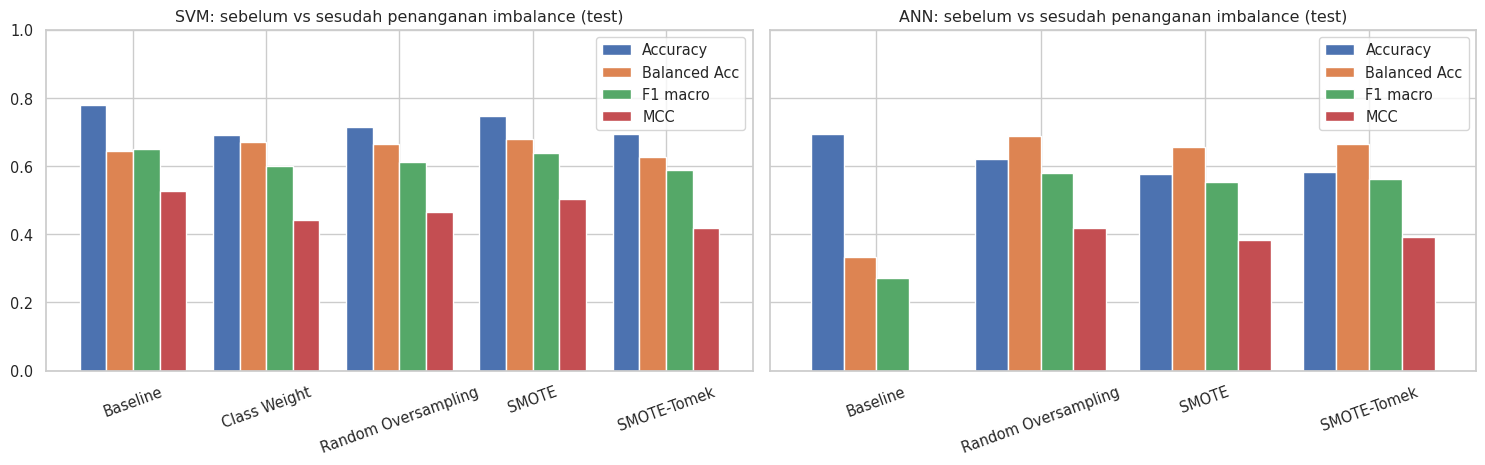

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), sharey=True)
for ax, m in zip(axes, STRATS):
    d = R[R.Model == m].set_index('Strategi')[['Test_Acc', 'Test_BalAcc', 'Test_F1', 'Test_MCC']]
    d.columns = ['Accuracy', 'Balanced Acc', 'F1 macro', 'MCC']
    d.plot.bar(ax=ax, width=0.8, rot=20); ax.set_title(f'{m}: sebelum vs sesudah penanganan imbalance (test)'); ax.set_xlabel('')
    ax.set_ylim(0, 1)
plt.tight_layout(); plt.show()

===== SVM + Baseline | {'model__C': 1000, 'model__gamma': 'scale'}
              precision    recall  f1-score   support

        Good       0.89      0.90      0.90       208
    Moderate       0.48      0.50      0.49        62
   Unhealthy       0.59      0.53      0.56        30

    accuracy                           0.78       300
   macro avg       0.66      0.64      0.65       300
weighted avg       0.78      0.78      0.78       300

===== ANN + SMOTE | {'model__alpha': 0.0001, 'model__hidden_layer_sizes': (64, 32)}
              precision    recall  f1-score   support

        Good       0.97      0.52      0.68       208
    Moderate       0.30      0.65      0.41        62
   Unhealthy       0.44      0.80      0.56        30

    accuracy                           0.58       300
   macro avg       0.57      0.66      0.55       300
weighted avg       0.78      0.58      0.61       300



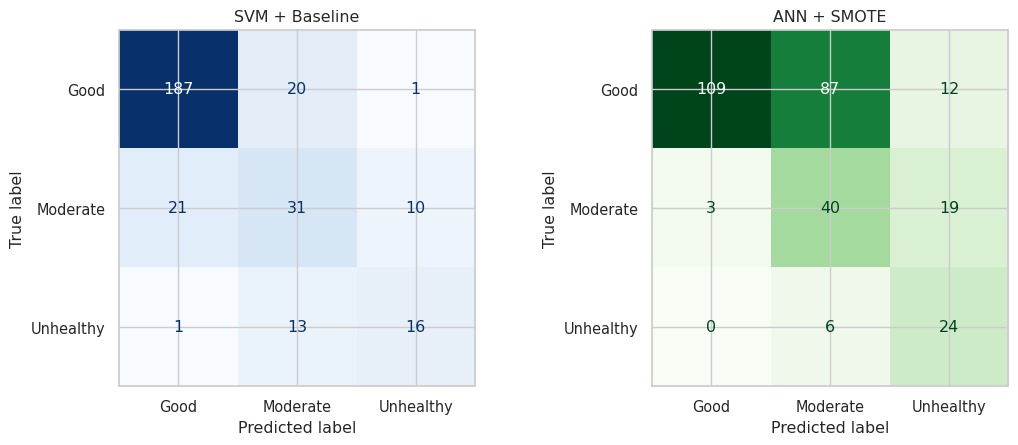

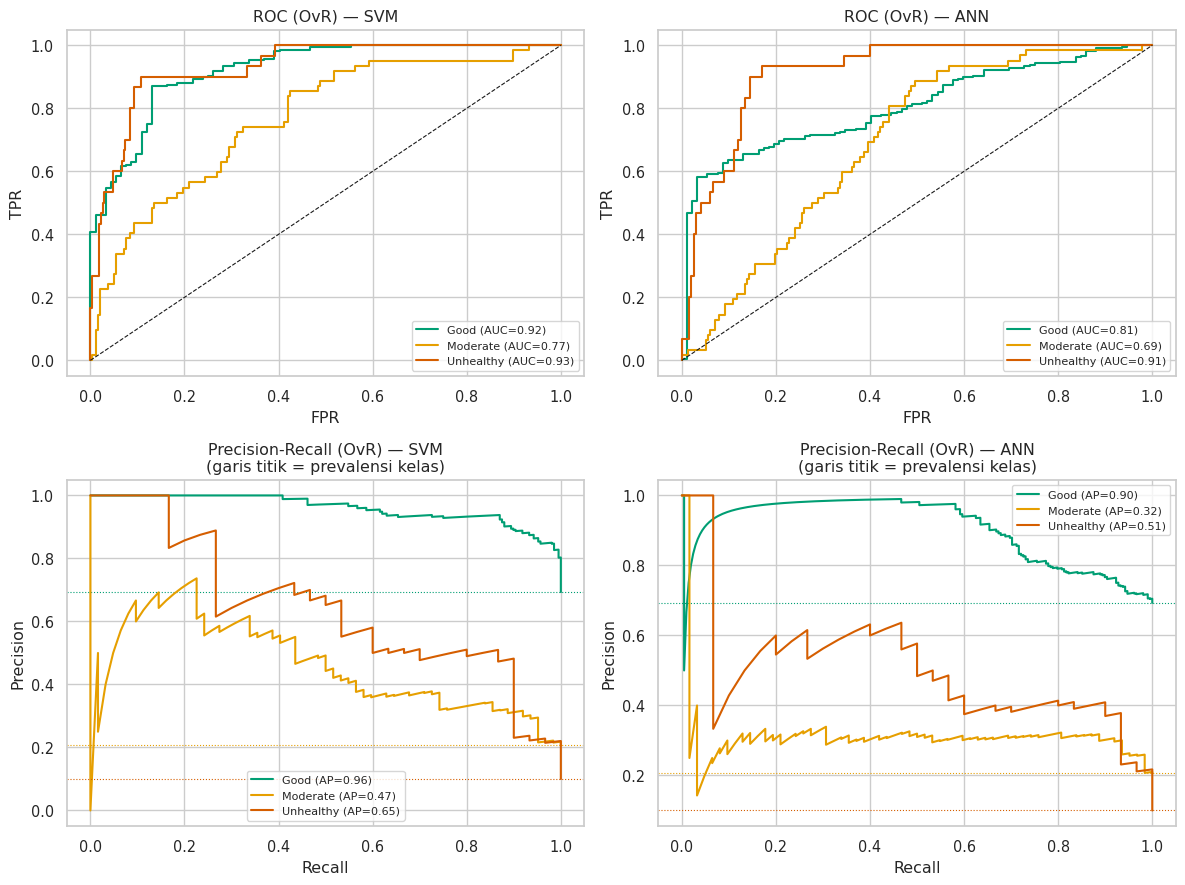

In [ ]:
best = {m: fits[(m, chosen[m])] for m in STRATS}
pred = {m: best[m].predict(X_test) for m in STRATS}

for m in STRATS:
    print(f'===== {m} + {chosen[m]} | {best[m].best_params_}')
    print(classification_report(y_test, pred[m], target_names=CLASSES, zero_division=0))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, m, cmap in zip(axes, STRATS, ['Blues', 'Greens']):
    ConfusionMatrixDisplay.from_predictions(y_test, pred[m], display_labels=CLASSES, cmap=cmap, ax=ax, colorbar=False)
    ax.set_title(f'{m} + {chosen[m]}')
plt.tight_layout(); plt.show()

Yb = label_binarize(y_test, classes=[0, 1, 2])
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for j, m in enumerate(STRATS):
    S = scores_of(best[m].best_estimator_, X_test)
    for k, c in enumerate(CLASSES):
        f, t, _ = roc_curve(Yb[:, k], S[:, k]); p, r, _ = precision_recall_curve(Yb[:, k], S[:, k])
        axes[0, j].plot(f, t, c=PALETTE[c], label=f'{c} (AUC={roc_auc_score(Yb[:, k], S[:, k]):.2f})')
        axes[1, j].plot(r, p, c=PALETTE[c], label=f'{c} (AP={average_precision_score(Yb[:, k], S[:, k]):.2f})')
        axes[1, j].axhline(Yb[:, k].mean(), c=PALETTE[c], ls=':', lw=0.8)
    axes[0, j].plot([0, 1], [0, 1], 'k--', lw=0.8); axes[0, j].set_title(f'ROC (OvR) — {m}')
    axes[1, j].set_title(f'Precision-Recall (OvR) — {m}\n(garis titik = prevalensi kelas)')
    axes[0, j].set_xlabel('FPR'); axes[0, j].set_ylabel('TPR'); axes[1, j].set_xlabel('Recall'); axes[1, j].set_ylabel('Precision')
    axes[0, j].legend(fontsize=8); axes[1, j].legend(fontsize=8)
plt.tight_layout(); plt.show()

### Inferensi statistik pada hasil
Test set kecil (kelas Unhealthy hanya ±30 observasi), sehingga angka tunggal tidak cukup. Berikut **selang kepercayaan bootstrap 95%**
untuk tiap model dan **bootstrap berpasangan** untuk selisih SVM − ANN (sampel ulang indeks test yang sama untuk kedua model).

In [ ]:
rng = np.random.default_rng(SEED)
yt = np.asarray(y_test); n = len(yt)
idx = rng.integers(0, n, size=(N_BOOT, n))
metric = {'F1 macro': lambda a, b: f1_score(a, b, average='macro', zero_division=0),
          'Balanced Acc': balanced_accuracy_score, 'MCC': matthews_corrcoef}

boot = {m: {k: np.array([f(yt[i], pred[m][i]) for i in idx]) for k, f in metric.items()} for m in STRATS}
rows = []
for k in metric:
    for m in STRATS:
        lo, hi = np.percentile(boot[m][k], [2.5, 97.5])
        rows.append({'Metrik': k, 'Model': f'{m} + {chosen[m]}', 'Estimasi': metric[k](yt, pred[m]), 'CI95 bawah': lo, 'CI95 atas': hi})
    d = boot['SVM'][k] - boot['ANN'][k]; lo, hi = np.percentile(d, [2.5, 97.5])
    rows.append({'Metrik': k, 'Model': 'Selisih SVM - ANN', 'Estimasi': metric[k](yt, pred['SVM']) - metric[k](yt, pred['ANN']),
                 'CI95 bawah': lo, 'CI95 atas': hi})
CI = pd.DataFrame(rows); display(CI.set_index(['Metrik', 'Model']).round(3))
print('Selisih dianggap berbeda nyata (pada 95%) bila selang selisih tidak memuat 0.')

Estimasi  CI95 bawah  CI95 atas
Metrik       Model                                             
F1 macro     SVM + Baseline        0.650       0.578      0.718
             ANN + SMOTE           0.552       0.490      0.613
             Selisih SVM - ANN     0.098       0.022      0.171
Balanced Acc SVM + Baseline        0.644       0.571      0.718
             ANN + SMOTE           0.656       0.588      0.719
             Selisih SVM - ANN    -0.012      -0.092      0.061
MCC          SVM + Baseline        0.526       0.435      0.614
             ANN + SMOTE           0.383       0.305      0.458
             Selisih SVM - ANN     0.143       0.039      0.240

Selisih dianggap berbeda nyata (pada 95%) bila selang selisih tidak memuat 0.


## G. Interpretasi dan diagnostik

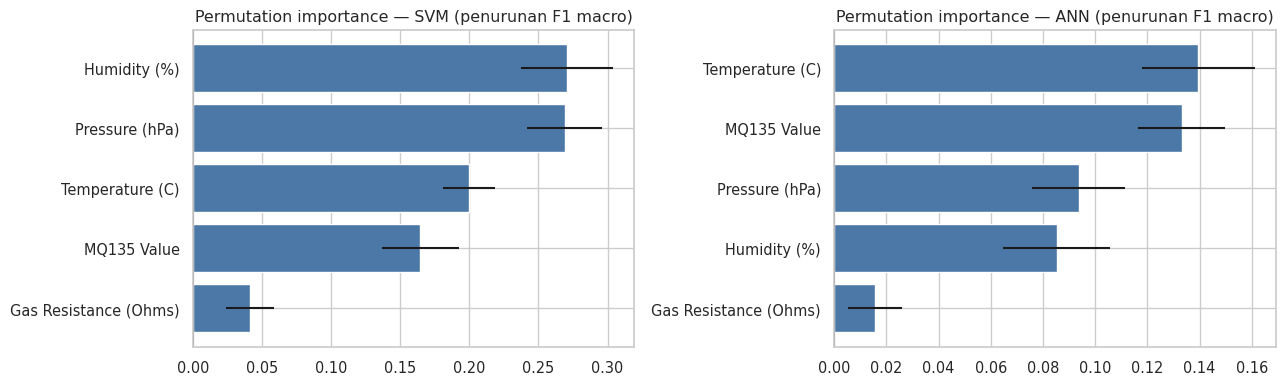

Korelasi tiap fitur dengan urutan waktu:
Temperature (C)         -0.01
Humidity (%)            -0.92
Pressure (hPa)          -0.99
Gas Resistance (Ohms)    0.03
MQ135 Value              0.63
CATATAN: fitur dengan |r| tinggi terhadap waktu (Pressure, Humidity) berperan sebagai PENANDA FASE WAKTU, bukan penyebab fisik kelas udara.


In [ ]:
# --- Permutation importance (model-agnostik; berlaku untuk SVM maupun ANN) ---
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, m in zip(axes, STRATS):
    pi = permutation_importance(best[m].best_estimator_, X_test, y_test, scoring='f1_macro',
                                n_repeats=30, random_state=SEED)
    o = np.argsort(pi.importances_mean)
    ax.barh(np.array(FEATURES)[o], pi.importances_mean[o], xerr=pi.importances_std[o], color='#4C78A8')
    ax.set_title(f'Permutation importance — {m} (penurunan F1 macro)'); ax.axvline(0, c='k', lw=0.6)
plt.tight_layout(); plt.show()
r_time = raw[FEATURES].apply(lambda c: np.corrcoef(np.arange(len(raw)), c)[0, 1]).round(2)
print('Korelasi tiap fitur dengan urutan waktu:'); print(r_time.to_string())
print('CATATAN: fitur dengan |r| tinggi terhadap waktu (Pressure, Humidity) berperan sebagai PENANDA FASE WAKTU, bukan penyebab fisik kelas udara.')

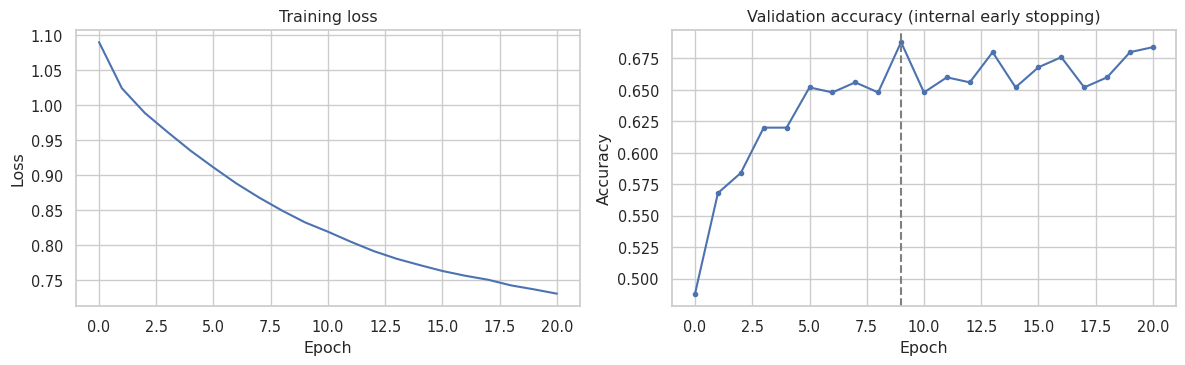

Arsitektur=(64, 32) | alpha=0.0001 | epoch berhenti=21 | val. terbaik=0.688
Catatan: split validasi internal diambil setelah resampling, sehingga skornya cenderung optimis.


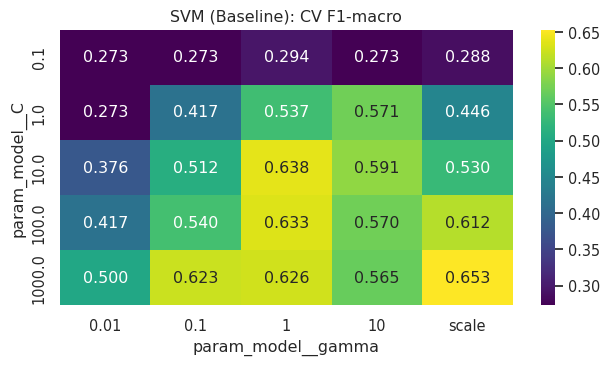

Train_F1  CV_F1  Test_F1  Gap_F1
Model Strategi                                             
SVM   Baseline                0.777  0.653    0.650   0.127
      Class Weight            0.760  0.641    0.601   0.159
      Random Oversampling     0.842  0.639    0.612   0.230
      SMOTE                   0.897  0.636    0.639   0.258
      SMOTE-Tomek             0.846  0.628    0.587   0.258
ANN   Baseline                0.273  0.307    0.273   0.000
      Random Oversampling     0.606  0.518    0.580   0.026
      SMOTE                   0.567  0.552    0.552   0.015
      SMOTE-Tomek             0.575  0.532    0.562   0.013

In [ ]:
# --- Diagnostik ANN: kurva loss & skor validasi (early stopping) ---
mlp = best['ANN'].best_estimator_.named_steps['model']
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(mlp.loss_curve_); ax[0].set(title='Training loss', xlabel='Epoch', ylabel='Loss')
ax[1].plot(mlp.validation_scores_, marker='o', ms=3); ax[1].axvline(np.argmax(mlp.validation_scores_), ls='--', c='gray')
ax[1].set(title='Validation accuracy (internal early stopping)', xlabel='Epoch', ylabel='Accuracy')
plt.tight_layout(); plt.show()
print(f'Arsitektur={mlp.hidden_layer_sizes} | alpha={mlp.alpha} | epoch berhenti={mlp.n_iter_} | val. terbaik={mlp.best_validation_score_:.3f}')
print('Catatan: split validasi internal diambil setelah resampling, sehingga skornya cenderung optimis.')

# --- Diagnostik SVM: CV F1 terhadap (C, gamma) ---
cr = pd.DataFrame(best['SVM'].cv_results_)
piv = cr.pivot_table(index='param_model__C', columns='param_model__gamma', values='mean_test_f1_macro')
plt.figure(figsize=(6.5, 3.8)); sns.heatmap(piv, annot=True, fmt='.3f', cmap='viridis')
plt.title(f'SVM ({chosen["SVM"]}): CV F1-macro'); plt.tight_layout(); plt.show()

# --- Overfitting: train vs CV vs test ---
display(R[['Model', 'Strategi', 'Train_F1', 'CV_F1', 'Test_F1', 'Gap_F1']].round(3).set_index(['Model', 'Strategi']))

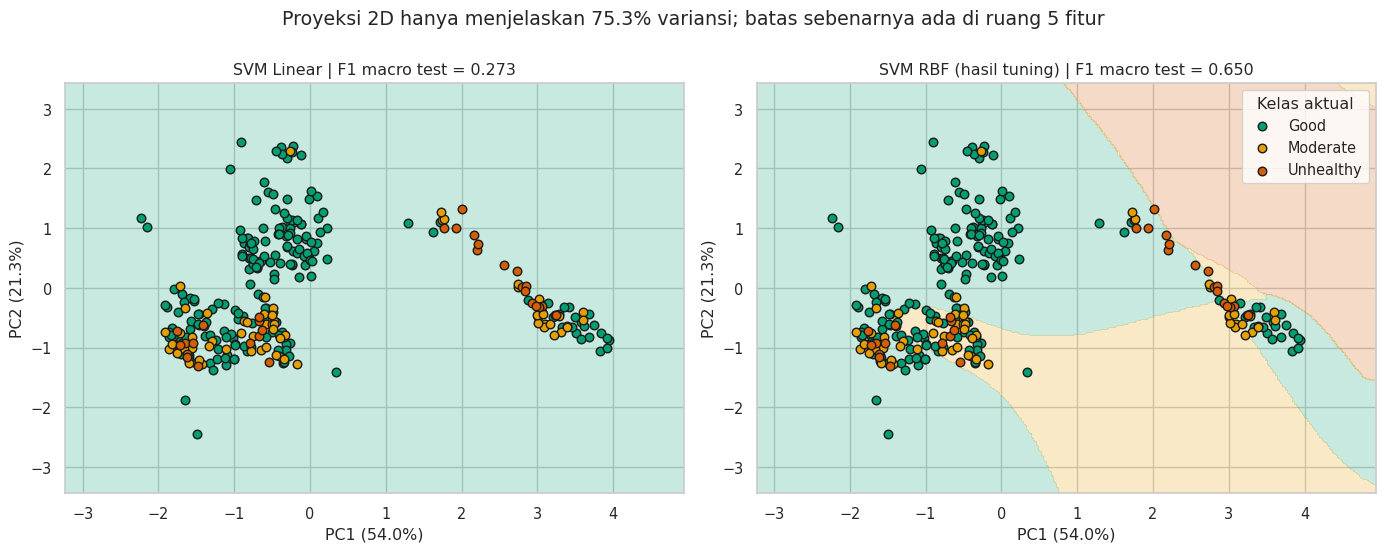

In [ ]:
# --- Decision boundary SVM pada proyeksi PCA 2D (Linear vs RBF), titik = data test ---
sc2 = StandardScaler().fit(X_train); pca = PCA(2).fit(sc2.transform(X_train)); Zte = pca.transform(sc2.transform(X_test))
gx, gy = np.meshgrid(np.linspace(Zte[:, 0].min() - 1, Zte[:, 0].max() + 1, 250),
                     np.linspace(Zte[:, 1].min() - 1, Zte[:, 1].max() + 1, 250))
grid = pd.DataFrame(sc2.inverse_transform(pca.inverse_transform(np.c_[gx.ravel(), gy.ravel()])), columns=FEATURES)

cw = 'balanced' if chosen['SVM'] == 'Class Weight' else None
lin = Pipeline([('scaler', StandardScaler()), ('model', SVC(kernel='linear', C=best['SVM'].best_params_['model__C'], class_weight=cw))]).fit(X_train, y_train)
cols = [PALETTE[c] for c in CLASSES]
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, (nm, mdl) in zip(axes, {'SVM Linear': lin, 'SVM RBF (hasil tuning)': best['SVM'].best_estimator_}.items()):
    ax.contourf(gx, gy, mdl.predict(grid).reshape(gx.shape), levels=[-.5, .5, 1.5, 2.5], colors=cols, alpha=.22)
    for k, c in enumerate(CLASSES): ax.scatter(*Zte[y_test == k].T, c=PALETTE[c], edgecolor='k', s=38, label=c)
    ax.set_title(f'{nm} | F1 macro test = {f1_score(y_test, mdl.predict(X_test), average="macro"):.3f}')
    ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)'); ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
axes[1].legend(title='Kelas aktual')
fig.suptitle(f'Proyeksi 2D hanya menjelaskan {pca.explained_variance_ratio_.sum()*100:.1f}% variansi; batas sebenarnya ada di ruang {len(FEATURES)} fitur', y=1.0)
plt.tight_layout(); plt.show()

Baseline "hanya waktu" dan validasi berblok waktu (PENTING)
Pertanyaan kritis: apakah model benar-benar memanfaatkan sensor, atau hanya mengenali posisi waktu dalam sesi?

Baseline waktu: model yang hanya diberi nomor urut observasi, tanpa satu pun sensor.
Random CV (diacak) vs Blocked CV (5 blok waktu berurutan, tanpa diacak). Pada blocked CV model diuji pada periode yang tidak berdekatan dengan data latih.
Majority baseline: selalu menebak kelas Good.

,F1 macro (CV acak),Bal.Acc (CV acak),F1 macro (CV blok waktu),Bal.Acc (CV blok waktu)
Model,,,,
Selalu tebak mayoritas,0.273,0.333,0.299,0.367
Hanya indeks waktu (kNN),0.746,0.724,0.297,0.461
SVM sensor (Baseline),0.644,0.630,0.311,0.439
ANN sensor (SMOTE),0.558,0.629,0.299,0.387


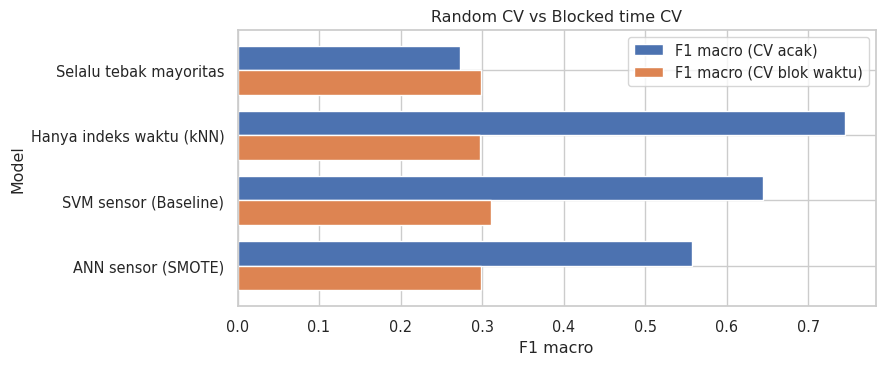

Baseline HANYA WAKTU (CV acak): F1 = 0.746  vs  SVM sensor = 0.644
Blocked time CV: waktu-saja F1 = 0.297 | SVM sensor F1 = 0.311


In [ ]:

from sklearn.model_selection import KFold, cross_validate
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import make_pipeline

rand_cv    = StratifiedKFold(N_FOLDS, shuffle=True, random_state=SEED)   # diacak (seperti sebelumnya)
blocked_cv = KFold(N_FOLDS, shuffle=False)                              # 5 blok waktu berurutan
time_X = pd.DataFrame({'indeks_waktu': np.arange(len(raw))})

cands = {
    'Selalu tebak mayoritas':        (DummyClassifier(strategy='most_frequent'), time_X),
    'Hanya indeks waktu (kNN)':      (make_pipeline(StandardScaler(), KNeighborsClassifier(15)), time_X),
    f'SVM sensor ({chosen["SVM"]})': (build('SVM', chosen['SVM']).set_params(**best['SVM'].best_params_), X_all),
    f'ANN sensor ({chosen["ANN"]})': (build('ANN', chosen['ANN']).set_params(**best['ANN'].best_params_), X_all),
}
sc_ = {'f1': 'f1_macro', 'bal': 'balanced_accuracy'}
rows = []
for name, (est, Xc) in cands.items():
    a = cross_validate(est, Xc, y_all, cv=rand_cv,    scoring=sc_)
    b = cross_validate(est, Xc, y_all, cv=blocked_cv, scoring=sc_)
    rows.append({'Model': name,
                 'F1 macro (CV acak)': a['test_f1'].mean(),    'Bal.Acc (CV acak)': a['test_bal'].mean(),
                 'F1 macro (CV blok waktu)': b['test_f1'].mean(), 'Bal.Acc (CV blok waktu)': b['test_bal'].mean()})
T = pd.DataFrame(rows).set_index('Model'); display(T.round(3))

ax = T[['F1 macro (CV acak)', 'F1 macro (CV blok waktu)']].plot.barh(figsize=(9, 3.8), width=0.75)
ax.set_xlabel('F1 macro'); ax.set_title('Random CV vs Blocked time CV'); ax.invert_yaxis(); plt.tight_layout(); plt.show()

tw, sv = T.loc['Hanya indeks waktu (kNN)'], T.loc[f'SVM sensor ({chosen["SVM"]})']
print(f'Baseline HANYA WAKTU (CV acak): F1 = {tw.iloc[0]:.3f}  vs  SVM sensor = {sv.iloc[0]:.3f}')
print(f'Blocked time CV: waktu-saja F1 = {tw.iloc[2]:.3f} | SVM sensor F1 = {sv.iloc[2]:.3f}')


## H. Uji ketahanan
**H1. Stabilitas inisialisasi ANN** : bobot awal acak memengaruhi hasil (Pertemuan 12). Model terpilih dilatih ulang dengan 10 seed.
**H2. Split berdasarkan waktu** : data berurutan ±6 detik: split acak membuat data uji bersebelahan dengan data latih (autokorelasi temporal).
Model dilatih pada 80% awal dan diuji pada 20% akhir dengan hyperparameter yang sama.

In [ ]:
# H1: seed ANN
sd = []
for s in range(10):
    p = build('ANN', chosen['ANN'], seed=s).set_params(**best['ANN'].best_params_).fit(X_train, y_train).predict(X_test)
    sd.append({'seed': s, 'F1 macro': f1_score(y_test, p, average='macro'), 'Balanced Acc': balanced_accuracy_score(y_test, p)})
sd = pd.DataFrame(sd); display(sd.describe().loc[['mean', 'std', 'min', 'max'], ['F1 macro', 'Balanced Acc']].round(3))

# H2: split waktu
cut = int(0.8 * len(raw)); Xa, Xb, ya, yb = X_all.iloc[:cut], X_all.iloc[cut:], y_all[:cut], y_all[cut:]
print('Distribusi kelas  train(awal):', np.bincount(ya, minlength=3), '| test(akhir):', np.bincount(yb, minlength=3))
rows = []
for m in STRATS:
    p = build(m, chosen[m]).set_params(**best[m].best_params_).fit(Xa, ya).predict(Xb)
    rows.append({'Model': f'{m} + {chosen[m]}', 'Acc': accuracy_score(yb, p), 'Balanced Acc': balanced_accuracy_score(yb, p),
                 'F1 macro (split waktu)': f1_score(yb, p, average='macro', zero_division=0),
                 'F1 macro (split acak)': R[(R.Model == m) & (R.Strategi == chosen[m])].Test_F1.iloc[0]})
display(pd.DataFrame(rows).round(3).set_index('Model'))

,F1 macro,Balanced Acc
mean,0.550,0.657
std,0.012,0.010
min,0.533,0.640
max,0.571,0.675


Distribusi kelas  train(awal): [844 236 120] | test(akhir): [197  71  32]


,Acc,Balanced Acc,F1 macro (split waktu),F1 macro (split acak)
Model,,,,
SVM + Baseline,0.27,0.344,0.167,0.650
ANN + SMOTE,0.33,0.342,0.232,0.552


## Ringkasan (dihasilkan dari hasil running di atas)

In [ ]:
def g(m, s, col): return R[(R.Model == m) & (R.Strategi == s)][col].iloc[0]
print(f'1. Imbalance: IR = {IR:.2f}. Model "selalu {n_k.idxmax()}" mencapai akurasi {accuracy_score(y_all, maj):.3f} tetapi balanced accuracy hanya {balanced_accuracy_score(y_all, maj):.3f}.')
for m in STRATS:
    if chosen[m] == 'Baseline':
        print(f'2. {m}: CV memilih Baseline (tanpa resampling) -> BalAcc/F1 test = {g(m,"Baseline","Test_BalAcc"):.3f}/{g(m,"Baseline","Test_F1"):.3f}; strategi imbalance tidak memberi keuntungan jelas.')
    else:
        print(f'2. {m}: Baseline BalAcc/F1 = {g(m,"Baseline","Test_BalAcc"):.3f}/{g(m,"Baseline","Test_F1"):.3f}  ->  {chosen[m]} = {g(m,chosen[m],"Test_BalAcc"):.3f}/{g(m,chosen[m],"Test_F1"):.3f}  (Acc {g(m,"Baseline","Test_Acc"):.3f} -> {g(m,chosen[m],"Test_Acc"):.3f})')
d = CI[(CI.Metrik == 'F1 macro') & (CI.Model == 'Selisih SVM - ANN')].iloc[0]
verdict = 'berbeda nyata' if (d['CI95 bawah'] > 0 or d['CI95 atas'] < 0) else 'TIDAK berbeda nyata'
print(f'3. Selisih F1 macro SVM-ANN = {d.Estimasi:.3f} (CI95 {d["CI95 bawah"]:.3f} s.d. {d["CI95 atas"]:.3f}) -> {verdict} pada tingkat 95%.')
print(f'4. Stabilitas ANN antar-seed: F1 macro {sd["F1 macro"].mean():.3f} +/- {sd["F1 macro"].std():.3f}.')
print(f'5. Baseline HANYA WAKTU (CV acak) F1 = {tw.iloc[0]:.3f} vs SVM sensor {sv.iloc[0]:.3f}; pada blocked time CV: waktu-saja {tw.iloc[2]:.3f}, SVM {sv.iloc[2]:.3f}. '
      'Jadi performa model pada split acak sebagian besar mencerminkan pengenalan fase waktu, bukan hubungan sensor -> kondisi udara.')
print('6. Keterbatasan: label relatif (persentil dataset); sesi pendek di satu lokasi; autokorelasi waktu; kelas minoritas kecil sehingga CI lebar; hasil split waktu jauh lebih rendah daripada split acak.')

1. Imbalance: IR = 6.85. Model "selalu Good" mencapai akurasi 0.694 tetapi balanced accuracy hanya 0.333.
2. SVM: CV memilih Baseline (tanpa resampling) -> BalAcc/F1 test = 0.644/0.650; strategi imbalance tidak memberi keuntungan jelas.
2. ANN: Baseline BalAcc/F1 = 0.333/0.273  ->  SMOTE = 0.656/0.552  (Acc 0.693 -> 0.577)
3. Selisih F1 macro SVM-ANN = 0.098 (CI95 0.022 s.d. 0.171) -> berbeda nyata pada tingkat 95%.
4. Stabilitas ANN antar-seed: F1 macro 0.550 +/- 0.012.
5. Baseline HANYA WAKTU (CV acak) F1 = 0.746 vs SVM sensor 0.644; pada blocked time CV: waktu-saja 0.297, SVM 0.311. Jadi performa model pada split acak sebagian besar mencerminkan pengenalan fase waktu, bukan hubungan sensor -> kondisi udara.
6. Keterbatasan: label relatif (persentil dataset); sesi pendek di satu lokasi; autokorelasi waktu; kelas minoritas kecil sehingga CI lebar; hasil split waktu jauh lebih rendah daripada split acak.
